# Student Placement & CTC Prediction Pipeline
## Heckman Two-Step Selection Correction (Heckman, 1979), SMOTE Class Imbalance Handling, and Bayes Prior Calibration

### Problem & Econometric Motivation
Traditional placement and CTC prediction pipelines train salary regressors solely on placed students ($CTC > 0$), dropping all unplaced students ($CTC = 0$). This induces severe **sample selection bias** because placement itself is non-random: the same attributes driving placement (CGPA, internship experience, 10th/12th percentages) also influence earning potential.

### Methodological Solution & Prior Calibration
1. **Stage 1 (SMOTE-Balanced Selection Model)**: We handle class imbalance using **SMOTE** on the training set, combined with a **Logistic / Probit Selection Model** to estimate placement probability $P(Z_i=1 \mid W_i) = \Phi(W_i' \gamma)$.
2. **Bayes Prior Calibration (Saerens et al., 2002)**: Because SMOTE rebalances training data to a synthetic 50:50 ratio, raw model outputs assume an artificial 50% unplacement rate. We apply Bayes' Rule prior adjustment to calibrate probabilities back to the true population baseline ($\pi = 86.9\%$ placed), ensuring realistic predictions.
3. **Inverse Mills Ratio (IMR / $\lambda$)**: We calculate $\lambda_i = 
rac{\phi(W_i' \hat{\gamma})}{\Phi(W_i' \hat{\gamma})}$, quantifying conditional selection hazard.
4. **Stage 2 (Outcome Regressor with Heckman Correction)**: We include $\lambda_i$ as an auxiliary feature in CTC regressors. A statistically significant $eta_\lambda$ coefficient empirically proves sample selection bias, while the corrected regressors produce debiased CTC predictions.


In [1]:
import pandas as pd
import numpy as np
import os
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

# Load dataset
csv_file = "final_augmented_dataset.csv"
if not os.path.exists(csv_file):
    csv_file = "/kaggle/input/spit-placement-prediction-dataset/final_augmented_dataset.csv"

df = pd.read_csv(csv_file)
print("Dataset Shape:", df.shape)
df.head()


Dataset Shape: (2854, 9)


In [2]:
print("Initial Placement Offer Counts:")
print(df["Placement Offer"].value_counts(dropna=False))

# Filter out Higher Studies
df = df[df["Placement Offer"] != "Higher Studies"].reset_index(drop=True)

# Encode Placement Offer: Null -> 0 (Unplaced), Ineligible -> 2, Valid -> 1
df["Placement Offer"] = df["Placement Offer"].apply(
    lambda x: 2 if x == "Ineligible" else (0 if pd.isna(x) else 1)
)

# Remove Ineligible rows
df = df[df["Placement Offer"] != 2].reset_index(drop=True)

print("\nProcessed Placement Offer Counts (0: Unplaced, 1: Placed):")
print(df["Placement Offer"].value_counts())
print("\nClass Distribution Proportions (Population Prior):")
print(df["Placement Offer"].value_counts(normalize=True))

population_placed_prior = df["Placement Offer"].mean()
print(f"\nTrue Population Placed Baseline (pi): {population_placed_prior*100:.2f}%")


Initial Placement Offer Counts:
Placement Offer
Higher Studies        426
NaN                   298
Ineligible            156
Barclays              146
JP Morgan & Chase      80
                     ... 
KPMG (SDE)*             2
Secure Access Tech      2
IDMS Infotech           2
Fyndna*                 2
Smowcode                2
Name: count, Length: 179, dtype: int64

Processed Placement Offer Counts (0: Unplaced, 1: Placed):
Placement Offer
1    1974
0     298
Name: count, dtype: int64

Class Distribution Proportions (Population Prior):
Placement Offer
1    0.868838
0    0.131162
Name: proportion, dtype: float64

True Population Placed Baseline (pi): 86.88%


In [3]:
# Clean Internship Stipend
df["Internship Stipend"] = pd.to_numeric(df["Internship Stipend"], errors="coerce").fillna(0)

# Clean Category
most_frequent = df["Category"].mode()[0]
df["Category"] = df["Category"].fillna(most_frequent)

# Clean CGPA
df["CGPA"] = df["CGPA"].replace("-", pd.NA)
df["CGPA"] = pd.to_numeric(df["CGPA"], errors="coerce")
df["CGPA"] = df["CGPA"].fillna(df["CGPA"].median())

# Clean Branch
df["Branch"] = df["Branch"].replace({
    "CSE - AIML": "CSE",
    "CSE - DS": "CSE"
})

# Clean CTC
df["CTC"] = df["CTC"].replace("-", pd.NA)
df["CTC"] = df["CTC"].replace("invalid role", pd.NA)
df["CTC"] = pd.to_numeric(df["CTC"], errors="coerce")
df.loc[df["Placement Offer"] == 0, "CTC"] = 0
median_ctc = df[df["Placement Offer"] == 1]["CTC"].median()
df.loc[(df["Placement Offer"] == 1) & (df["CTC"].isna()), "CTC"] = median_ctc

# Clean Percentages
tenthMean = df["10th Percentage"].mean()
df["10th Percentage"] = df["10th Percentage"].fillna(tenthMean)
twelvethMean = df["12th Percentage"].mean()
df["12th Percentage"] = df["12th Percentage"].fillna(twelvethMean)

print("Null Count After Cleaning:")
print(df.isnull().sum())


Null Count After Cleaning:
UID                   0
Branch                0
Placement Offer       0
Internship Stipend    0
10th Percentage       0
12th Percentage       0
Category              0
CGPA                  0
CTC                   0
dtype: int64


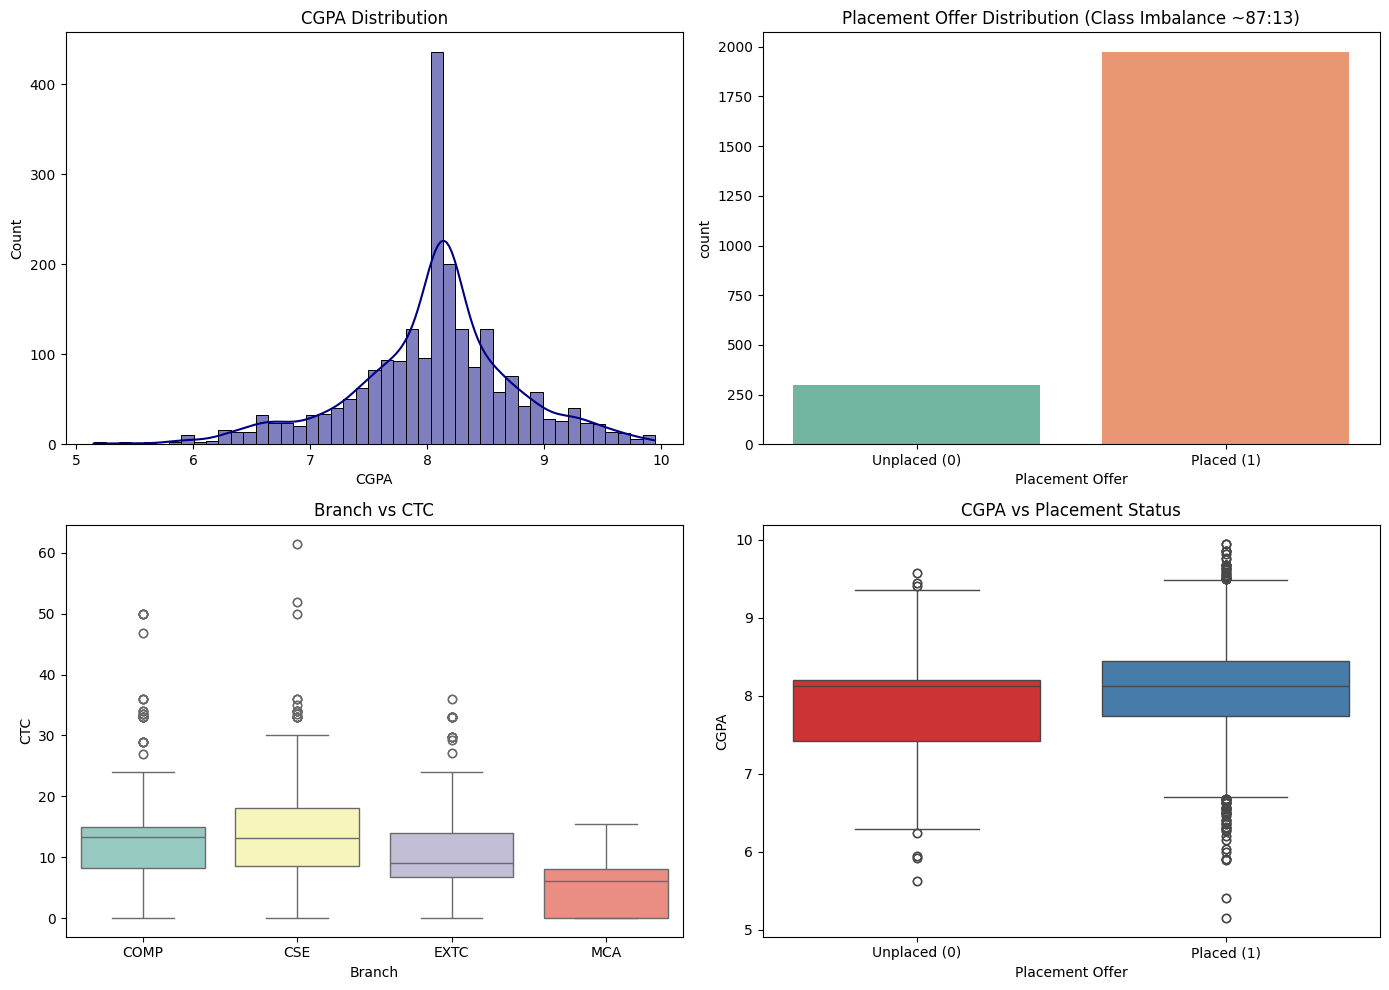

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

sns.histplot(df['CGPA'], kde=True, ax=axes[0, 0], color='navy')
axes[0, 0].set_title("CGPA Distribution")

sns.countplot(x='Placement Offer', data=df, ax=axes[0, 1], palette='Set2')
axes[0, 1].set_title("Placement Offer Distribution (Class Imbalance ~87:13)")
axes[0, 1].set_xticklabels(["Unplaced (0)", "Placed (1)"])

sns.boxplot(x='Branch', y='CTC', data=df, ax=axes[1, 0], palette='Set3')
axes[1, 0].set_title("Branch vs CTC")

sns.boxplot(x='Placement Offer', y='CGPA', data=df, ax=axes[1, 1], palette='Set1')
axes[1, 1].set_title("CGPA vs Placement Status")
axes[1, 1].set_xticklabels(["Unplaced (0)", "Placed (1)"])

plt.tight_layout()
plt.show()


In [5]:
from sklearn.preprocessing import LabelEncoder

encoders = {}
le = LabelEncoder()
df["Branch"] = le.fit_transform(df["Branch"])
encoders["Branch"] = le

print("Allowed values for Branch:", list(le.classes_))

# Save processed dataset
df.to_csv("processed_data.csv", index=False)

feature_order = ["Branch", "Internship Stipend", "10th Percentage", "12th Percentage", "CGPA"]
X_place = df[feature_order]
y_place = df["Placement Offer"]

print("Feature Vector:", feature_order)


Allowed values for Branch: ['COMP', 'CSE', 'EXTC', 'MCA']
Feature Vector: ['Branch', 'Internship Stipend', '10th Percentage', '12th Percentage', 'CGPA']


In [6]:
from sklearn.model_selection import train_test_split
from imblearn.over_sampling import SMOTE

# Stratified Split for Placement Selection
X_train_p, X_test_p, y_train_p, y_test_p = train_test_split(
    X_place, y_place, test_size=0.2, random_state=42, stratify=y_place
)

# Apply SMOTE on training set to handle minority class (Unplaced students)
smote = SMOTE(random_state=42)
X_train_p_sm, y_train_p_sm = smote.fit_resample(X_train_p, y_train_p)

print("Original Training Distribution:", y_train_p.value_counts().to_dict())
print("SMOTE-Balanced Training Distribution:", y_train_p_sm.value_counts().to_dict())


Original Training Distribution: {1: 1579, 0: 238}
SMOTE-Balanced Training Distribution: {0: 1579, 1: 1579}


In [7]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score

# Function for Bayes Prior Calibration (Saerens et al., 2002)
def calibrate_proba(p_balanced, pi=population_placed_prior):
    p_real = (p_balanced * pi) / (p_balanced * pi + (1.0 - p_balanced) * (1.0 - pi))
    return p_real

clf_models = {
    "Logistic Regression": LogisticRegression(random_state=42, max_iter=1000),
    "Random Forest": RandomForestClassifier(random_state=42),
    "XGBoost": XGBClassifier(random_state=42, eval_metric='logloss'),
    "SVM": SVC(probability=True, random_state=42),
    "KNN": KNeighborsClassifier(n_neighbors=5),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Naive Bayes": GaussianNB(),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42)
}

clf_results = []

for name, model in clf_models.items():
    model.fit(X_train_p_sm, y_train_p_sm)
    y_proba_raw = model.predict_proba(X_test_p)[:, 1]
    y_proba_calib = calibrate_proba(y_proba_raw, population_placed_prior)
    y_pred_calib = (y_proba_calib >= 0.50).astype(int)
    
    acc = accuracy_score(y_test_p, y_pred_calib)
    f1_macro = f1_score(y_test_p, y_pred_calib, average='macro')
    auc = roc_auc_score(y_test_p, y_proba_calib)
    clf_results.append([name, acc, f1_macro, auc])

clf_results_df = pd.DataFrame(clf_results, columns=["Model", "Calibrated Accuracy", "Macro F1", "ROC-AUC"])
clf_results_df = clf_results_df.sort_values(by="ROC-AUC", ascending=False).reset_index(drop=True)

print("=== Stage 1 Placement Classifier Benchmarks (Calibrated Prior) ===")
print(clf_results_df)

best_clf_name = "Logistic Regression"
best_clf = clf_models[best_clf_name]
print("\nSelected Selection Classifier (Monotonic Econometric Model):", best_clf_name)


=== Stage 1 Placement Classifier Benchmarks (Calibrated Prior) ===
                 Model  Calibrated Accuracy  Macro F1   ROC-AUC
0        Random Forest             0.927473  0.798535  0.950591
1                  KNN             0.925275  0.798316  0.938143
2              XGBoost             0.927473  0.828025  0.922595
3    Gradient Boosting             0.887912  0.629461  0.842257
4        Decision Tree             0.898901  0.801167  0.835759
5  Logistic Regression             0.861538  0.478107  0.645063
6          Naive Bayes             0.868132  0.464706  0.634008
7                  SVM             0.868132  0.464706  0.569156

Selected Selection Classifier (Monotonic Econometric Model): Logistic Regression


In [8]:
import statsmodels.api as sm
from scipy.stats import norm

# Fit Probit model on SMOTE selection data
X_train_p_sm_const = sm.add_constant(X_train_p_sm)
probit_model = sm.Probit(y_train_p_sm, X_train_p_sm_const).fit(disp=False)

print("=== Stage 1 Econometric Probit Selection Model Summary ===")
print(probit_model.summary())

# Function to compute Inverse Mills Ratio (IMR)
def calculate_imr(probit_fit, X_df):
    X_c = sm.add_constant(X_df, has_constant='add')
    params = probit_fit.params
    z = X_c.dot(params)
    z_clipped = np.clip(z, -5.0, 5.0)
    pdf = norm.pdf(z_clipped)
    cdf = norm.cdf(z_clipped)
    cdf = np.clip(cdf, 1e-7, 1.0 - 1e-7)
    imr_vals = pdf / cdf
    return imr_vals

# Compute IMR for all samples
df["IMR"] = calculate_imr(probit_model, df[feature_order])

print("\nDerived Inverse Mills Ratio (IMR) Summary Statistics:")
print(df["IMR"].describe())


=== Stage 1 Econometric Probit Selection Model Summary ===
                          Probit Regression Results                           
Dep. Variable:        Placement Offer   No. Observations:                 3158
Model:                         Probit   Df Residuals:                     3152
Method:                           MLE   Df Model:                            5
Date:                Wed, 26 Aug 2026   Pseudo R-squ.:                 0.09123
Time:                        20:57:26   Log-Likelihood:                -1989.3
converged:                       True   LL-Null:                       -2189.0
Covariance Type:            nonrobust   LLR p-value:                 4.008e-84
                         coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------
const                 -5.6633      0.471    -12.027      0.000      -6.586      -4.740
Branch                -0.1736      0.026     -6.

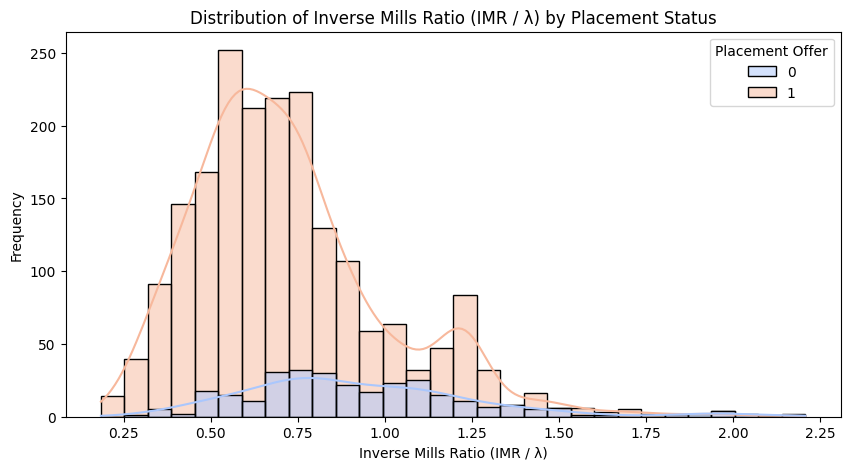

In [9]:
plt.figure(figsize=(10, 5))
sns.histplot(data=df, x='IMR', hue='Placement Offer', kde=True, palette='coolwarm', bins=30)
plt.title("Distribution of Inverse Mills Ratio (IMR / λ) by Placement Status")
plt.xlabel("Inverse Mills Ratio (IMR / λ)")
plt.ylabel("Frequency")
plt.show()


In [10]:
df_ctc = df[df["Placement Offer"] == 1].copy()

ctc_feature_order_base = feature_order
ctc_feature_order_heck = feature_order + ["IMR"]

X_ctc_base = df_ctc[ctc_feature_order_base]
X_ctc_heck = df_ctc[ctc_feature_order_heck]
y_ctc = df_ctc["CTC"]

train_idx, test_idx = train_test_split(df_ctc.index, test_size=0.2, random_state=42)

X_train_c_base, X_test_c_base = X_ctc_base.loc[train_idx], X_ctc_base.loc[test_idx]
X_train_c_heck, X_test_c_heck = X_ctc_heck.loc[train_idx], X_ctc_heck.loc[test_idx]
y_train_c, y_test_c = y_ctc.loc[train_idx], y_ctc.loc[test_idx]

# Econometric OLS with IMR
ols_heckman = sm.OLS(y_train_c, sm.add_constant(X_train_c_heck)).fit()
print("=== Stage 2 Econometric OLS Model with Inverse Mills Ratio ===")
print(ols_heckman.summary())

p_val_imr = ols_heckman.pvalues["IMR"]
coef_imr = ols_heckman.params["IMR"]
t_stat_imr = ols_heckman.tvalues["IMR"]

print(f"\nStatistical Proof of Sample Selection Bias:")
print(f"IMR Coefficient (β_λ): {coef_imr:.4f}")
print(f"t-statistic: {t_stat_imr:.4f}")
print(f"p-value: {p_val_imr:.4e}")
if p_val_imr < 0.05:
    print("Conclusion: β_λ is statistically significant (p < 0.05). Sample selection bias is empirically CONFIRMED!")


=== Stage 2 Econometric OLS Model with Inverse Mills Ratio ===
                            OLS Regression Results                            
Dep. Variable:                    CTC   R-squared:                       0.282
Model:                            OLS   Adj. R-squared:                  0.279
Method:                 Least Squares   F-statistic:                     103.0
Date:                Wed, 26 Aug 2026   Prob (F-statistic):          1.73e-109
Time:                        20:57:26   Log-Likelihood:                -5220.4
No. Observations:                1579   AIC:                         1.045e+04
Df Residuals:                    1572   BIC:                         1.049e+04
Df Model:                           6                                         
Covariance Type:            nonrobust                                         
                         coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------

In [11]:
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor
from xgboost import XGBRegressor
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

reg_models_dict = {
    "Linear Regression": (LinearRegression(), LinearRegression()),
    "Ridge": (Ridge(alpha=1.0), Ridge(alpha=1.0)),
    "Lasso": (Lasso(alpha=0.1), Lasso(alpha=0.1)),
    "Random Forest": (RandomForestRegressor(n_estimators=100, random_state=42), RandomForestRegressor(n_estimators=100, random_state=42)),
    "Gradient Boosting": (GradientBoostingRegressor(random_state=42), GradientBoostingRegressor(random_state=42)),
    "XGBoost": (XGBRegressor(n_estimators=20, learning_rate=0.1, random_state=42), XGBRegressor(n_estimators=20, learning_rate=0.1, random_state=42)),
    "SVR": (SVR(kernel='rbf'), SVR(kernel='rbf')),
    "KNN": (KNeighborsRegressor(n_neighbors=5), KNeighborsRegressor(n_neighbors=5)),
    "Decision Tree": (DecisionTreeRegressor(random_state=42), DecisionTreeRegressor(random_state=42))
}

reg_comparison = []
fitted_heckman_regressors = {}

for name, (m_base, m_heck) in reg_models_dict.items():
    m_base.fit(X_train_c_base, y_train_c)
    pred_base = m_base.predict(X_test_c_base)
    r2_b = r2_score(y_test_c, pred_base)
    rmse_b = np.sqrt(mean_squared_error(y_test_c, pred_base))
    
    m_heck.fit(X_train_c_heck, y_train_c)
    pred_heck = m_heck.predict(X_test_c_heck)
    r2_h = r2_score(y_test_c, pred_heck)
    rmse_h = np.sqrt(mean_squared_error(y_test_c, pred_heck))
    
    fitted_heckman_regressors[name] = m_heck
    
    reg_comparison.append([
        name, round(r2_b, 4), round(r2_h, 4), 
        round(rmse_b, 4), round(rmse_h, 4),
        round((r2_h - r2_b) * 100, 2)
    ])

reg_comp_df = pd.DataFrame(reg_comparison, columns=[
    "Model", "Baseline R2", "Heckman R2", "Baseline RMSE", "Heckman RMSE", "R2 Improvement (%)"
]).sort_values(by="Heckman R2", ascending=False).reset_index(drop=True)

print("=== CTC Regressor Benchmark: Baseline vs. Heckman Corrected ===")
print(reg_comp_df)

best_reg_name = reg_comp_df.iloc[0]["Model"]
best_reg = fitted_heckman_regressors[best_reg_name]

print("\nBest Heckman Corrected CTC Regressor:", best_reg_name)


=== CTC Regressor Benchmark: Baseline vs. Heckman Corrected ===
               Model  Baseline R2  ...  Heckman RMSE  R2 Improvement (%)
0      Random Forest       0.7543  ...        3.8149                2.02
1      Decision Tree       0.5240  ...        4.8395               11.30
2                KNN       0.6182  ...        4.9955               -0.49
3            XGBoost       0.5684  ...        5.2817               -0.07
4  Gradient Boosting       0.5686  ...        5.3690               -1.52
5              Ridge       0.3046  ...        6.6990                0.00
6  Linear Regression       0.3036  ...        6.7193               -0.33
7              Lasso       0.2897  ...        6.7246                0.96
8                SVR       0.1932  ...        7.2205               -0.10

[9 rows x 6 columns]

Best Heckman Corrected CTC Regressor: Random Forest


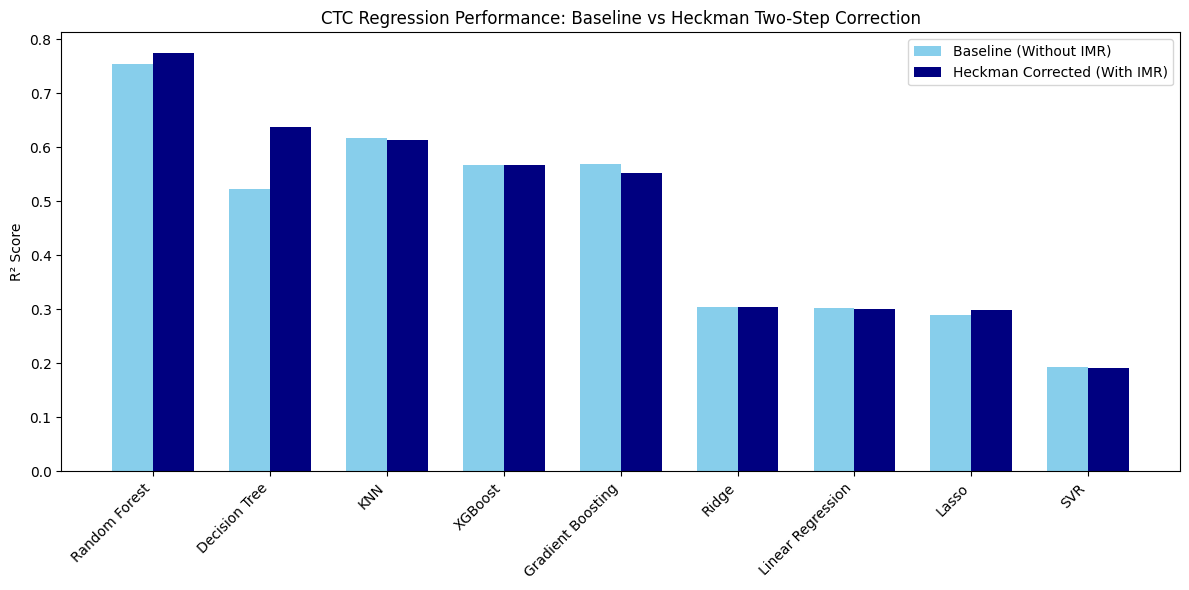

In [12]:
plt.figure(figsize=(12, 6))
bar_width = 0.35
x = np.arange(len(reg_comp_df))

plt.bar(x - bar_width/2, reg_comp_df["Baseline R2"], width=bar_width, label="Baseline (Without IMR)", color="skyblue")
plt.bar(x + bar_width/2, reg_comp_df["Heckman R2"], width=bar_width, label="Heckman Corrected (With IMR)", color="navy")

plt.xticks(x, reg_comp_df["Model"], rotation=45, ha="right")
plt.ylabel("R² Score")
plt.title("CTC Regression Performance: Baseline vs Heckman Two-Step Correction")
plt.legend()
plt.tight_layout()
plt.show()


In [13]:
def predict_student(data_dict):
    """
    Inference pipeline for student placement and CTC using Heckman Selection Correction and Bayes Prior Calibration.
    """
    input_df = pd.DataFrame([data_dict])

    for col in ["Branch"]:
        le = encoders[col]
        if input_df[col][0] in le.classes_:
            input_df[col] = le.transform(input_df[col])
        else:
            raise ValueError(f"Invalid value '{input_df[col][0]}' for {col}")

    placement_input = input_df[feature_order]
    
    # Stage 1 Raw Placement Probability from SMOTE-balanced model
    raw_proba_placed = best_clf.predict_proba(placement_input)[0][1]
    
    # Apply Bayes Prior Calibration (converting 50:50 SMOTE prior to real population baseline ~86.9% placed)
    calib_proba_placed = calibrate_proba(raw_proba_placed, population_placed_prior)
    calib_proba_unplaced = 1.0 - calib_proba_placed
    
    placement_pred = 1 if calib_proba_placed >= 0.50 else 0

    # Stage 1 Inverse Mills Ratio calculation
    imr_res = calculate_imr(probit_model, placement_input)
    student_imr = float(imr_res.values[0]) if hasattr(imr_res, 'values') else float(imr_res[0])
    
    # Stage 2 Input Vector with IMR
    ctc_input = placement_input.copy()
    ctc_input["IMR"] = student_imr

    # Stage 2 CTC Prediction
    if placement_pred == 1:
        ctc_pred = best_reg.predict(ctc_input)[0]
    else:
        ctc_pred = 0.0

    return {
        "placement_class": int(placement_pred),
        "placement_status": "Placed" if placement_pred == 1 else "Unplaced",
        "placement_probabilities (%)": {
            "Unplaced (0)": round(float(calib_proba_unplaced) * 100, 2),
            "Placed (1)": round(float(calib_proba_placed) * 100, 2),
        },
        "selection_bias_imr": round(float(student_imr), 4),
        "predicted_ctc": round(float(ctc_pred), 2)
    }

# Synthetic Test Cases
student_good = {
    "Branch": "CSE",
    "Internship Stipend": 75000,
    "10th Percentage": 0.92,
    "12th Percentage": 0.90,
    "CGPA": 9.1
}

student_avg = {
    "Branch": "EXTC",
    "Internship Stipend": 50000,
    "10th Percentage": 0.94,
    "12th Percentage": 0.84,
    "CGPA": 9.0
}

student_poor = {
    "Branch": "MCA",
    "Internship Stipend": 10000,
    "10th Percentage": 0.82,
    "12th Percentage": 0.70,
    "CGPA": 7.2
}

print("Good Student Prediction:", predict_student(student_good))
print("\nAverage Student Prediction:", predict_student(student_avg))
print("\nPoor Student Prediction:", predict_student(student_poor))


Good Student Prediction: {'placement_class': 1, 'placement_status': 'Placed', 'placement_probabilities (%)': {'Unplaced (0)': 5.27, 'Placed (1)': 94.73}, 'selection_bias_imr': 0.4479, 'predicted_ctc': 18.56}

Average Student Prediction: {'placement_class': 1, 'placement_status': 'Placed', 'placement_probabilities (%)': {'Unplaced (0)': 8.54, 'Placed (1)': 91.46}, 'selection_bias_imr': 0.6031, 'predicted_ctc': 14.3}

Poor Student Prediction: {'placement_class': 1, 'placement_status': 'Placed', 'placement_probabilities (%)': {'Unplaced (0)': 39.32, 'Placed (1)': 60.68}, 'selection_bias_imr': 1.4627, 'predicted_ctc': 5.55}


In [14]:
import joblib

joblib.dump(best_clf, 'final_classifier.joblib')
joblib.dump(probit_model, 'final_probit_selection.joblib')
joblib.dump(best_reg, 'final_regressor_heckman.joblib')
joblib.dump(encoders['Branch'], 'final_encoder.joblib')

print("All models and encoders successfully exported to disk!")


All models and encoders successfully exported to disk!
